## CE2 Phase 6: Regression Metrics & Error Analysis

### 1. Mathematical Definitions of Regression Metrics
To objectively evaluate and compare regression models for continuous age prediction, we utilize four standard statistical metrics:

1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   - Measures the average absolute magnitude of prediction errors in the original units (years).
   - Treats all errors linearly regardless of their direction or scale.

2. **Mean Squared Error (MSE):**
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
   - Measures the average squared difference between actual and predicted values (years$^2$).
   - Heavily penalizes large deviations due to quadratic scaling.

3. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
   - Returns the quadratic error back to the original interpretable units (years).
   - Sensitive to outliers and extreme prediction misses.

4. **Coefficient of Determination ($R^2$ Score):**
   $$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}} = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$
   - Quantifies the proportion of variance in the target variable explained by the feature inputs relative to a naive horizontal line predicting the mean age ($\bar{y}$).

---

### 2. Properties, Constraints & Outlier Sensitivity
* **Negative $R^2$ on Test Data:** While $R^2$ is bounded within $[0, 1]$ on training data when an intercept is included, it can become **negative** on unseen holdout test data. A negative $R^2$ occurs when $SS_{\text{res}} > SS_{\text{tot}}$, proving that the model's predictions have larger error variance than simply guessing the training dataset mean age for every individual.
* **Mathematical Bound ($\text{RMSE} \ge \text{MAE}$):** By Jensen's inequality and the Cauchy-Schwarz inequality, $\text{RMSE} \ge \text{MAE}$ holds strictly for all data distributions.
* **The Error Gap ($\text{RMSE} - \text{MAE}$):** Because squaring penalizes larger errors disproportionately, a wider discrepancy between RMSE and MAE directly reflects the presence of severe outlier prediction errors. A smaller gap signifies relatively uniform error magnitudes across test instances.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_validate, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure relative paths work from project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Load unscaled and scaled datasets
X_train = pd.read_csv("data/processed/X_train.csv")
X_test = pd.read_csv("data/processed/X_test.csv")
X_train_scaled = pd.read_csv("data/processed/X_train_scaled.csv")
X_test_scaled = pd.read_csv("data/processed/X_test_scaled.csv")
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
y_test = pd.read_csv("data/processed/y_test.csv")["age"]

# Define feature partitions
continuous_cols = [
    'eye_distance', 'mouth_width', 'face_width', 'face_height',
    'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio'
]
dummy_cols = ['gender_1', 'race_1', 'race_2', 'race_3', 'race_4']

# Drop reference categories (gender_0, race_0) to prevent the dummy variable trap (perfect multicollinearity)
X_train_mlr = X_train.drop(columns=["gender_0", "race_0"])
X_test_mlr = X_test.drop(columns=["gender_0", "race_0"])
X_train_mlr_s = X_train_scaled.drop(columns=["gender_0", "race_0"])
X_test_mlr_s = X_test_scaled.drop(columns=["gender_0", "race_0"])

print(f"X_train_mlr (unscaled) shape:   {X_train_mlr.shape}")
print(f"X_test_mlr (unscaled) shape:    {X_test_mlr.shape}")
print(f"X_train_mlr_s (scaled) shape:   {X_train_mlr_s.shape}")
print(f"X_test_mlr_s (scaled) shape:    {X_test_mlr_s.shape}")
print(f"y_train shape:                  {y_train.shape}")
print(f"y_test shape:                   {y_test.shape}")


X_train_mlr (unscaled) shape:   (2398, 12)
X_test_mlr (unscaled) shape:    (600, 12)
X_train_mlr_s (scaled) shape:   (2398, 12)
X_test_mlr_s (scaled) shape:    (600, 12)
y_train shape:                  (2398,)
y_test shape:                   (600,)



In [2]:
# Load existing CE2 model results
df_results = pd.read_csv("data/processed/ce2_model_results.csv")

# Baseline reference values
baseline_mae = df_results.loc[df_results["Model"] == "Baseline (Mean)", "Test_MAE"].values[0]
baseline_rmse = df_results.loc[df_results["Model"] == "Baseline (Mean)", "Test_RMSE"].values[0]

# Add derived gain columns relative to naive mean baseline
df_results["MAE_gain_vs_baseline"] = baseline_mae - df_results["Test_MAE"]
df_results["RMSE_gain_pct"] = ((baseline_rmse - df_results["Test_RMSE"]) / baseline_rmse) * 100.0

display_cols = [
    "Model", "Train_MAE", "Test_MAE", "MAE_gain_vs_baseline",
    "Train_RMSE", "Test_RMSE", "RMSE_gain_pct", "Train_R2", "Test_R2"
]
print("CE2 Cumulative Model Performance Summary (with Baseline Gains):")
print(df_results[display_cols].round(4).to_string(index=False))


CE2 Cumulative Model Performance Summary (with Baseline Gains):
                           Model  Train_MAE  Test_MAE  MAE_gain_vs_baseline  Train_RMSE  Test_RMSE  RMSE_gain_pct  Train_R2  Test_R2
                 Baseline (Mean)    15.5015   16.5798                0.0000     20.0591    21.0996         0.0000    0.0000  -0.0021
   Simple LR (face_aspect_ratio)    15.2493   16.1086                0.4712     19.3774    20.3385         3.6069    0.0668   0.0689
      Multiple Linear Regression    13.8583   14.7200                1.8598     18.1997    19.1813         9.0916    0.1768   0.1719
Polynomial Regression (degree 2)    13.6784   14.6535                1.9263     17.9914    19.1044         9.4561    0.1955   0.1785



In [3]:
# Refit Multiple Linear Regression on scaled data
mlr_model = LinearRegression().fit(X_train_mlr_s, y_train)
y_pred_mlr = mlr_model.predict(X_test_mlr_s)
test_r2_mlr = r2_score(y_test, y_pred_mlr)

# Refit Degree-2 Polynomial Pipeline on scaled data
poly2_pipe_scaled = Pipeline([
    ("poly_prep", ColumnTransformer([
        ("poly", PolynomialFeatures(degree=2, include_bias=False), continuous_cols),
        ("dummies", "passthrough", dummy_cols)
    ])),
    ("reg", LinearRegression())
])
poly2_pipe_scaled.fit(X_train_mlr_s, y_train)
y_pred_poly = poly2_pipe_scaled.predict(X_test_mlr_s)
test_r2_poly = r2_score(y_test, y_pred_poly)

# Verification against ce2_model_results.csv
expected_mlr_r2 = df_results.loc[df_results["Model"] == "Multiple Linear Regression", "Test_R2"].values[0]
expected_poly_r2 = df_results.loc[df_results["Model"] == "Polynomial Regression (degree 2)", "Test_R2"].values[0]

diff_mlr = abs(test_r2_mlr - expected_mlr_r2)
diff_poly = abs(test_r2_poly - expected_poly_r2)

print(f"MLR Test R²:       {test_r2_mlr:.4f} (Expected: {expected_mlr_r2:.4f}, Abs Diff: {diff_mlr:.6f})")
print(f"Poly (deg 2) R²:   {test_r2_poly:.4f} (Expected: {expected_poly_r2:.4f}, Abs Diff: {diff_poly:.6f})")

if diff_mlr > 0.001:
    print("WARNING: Multiple Linear Regression Test R² discrepancy exceeds 0.001!")
else:
    print("Verification Passed: Multiple Linear Regression Test R² perfectly verified.")

if diff_poly > 0.001:
    print("WARNING: Polynomial Regression Test R² discrepancy exceeds 0.001!")
else:
    print("Verification Passed: Polynomial Regression Test R² perfectly verified.")


MLR Test R²:       0.1719 (Expected: 0.1719, Abs Diff: 0.000000)
Poly (deg 2) R²:   0.1785 (Expected: 0.1785, Abs Diff: 0.000000)
Verification Passed: Multiple Linear Regression Test R² perfectly verified.
Verification Passed: Polynomial Regression Test R² perfectly verified.



Residual Summary Statistics on Test Set:
Multiple LR:           Mean = 1.1081, Std = 19.1652, Skew = 0.7323
Polynomial (degree 2): Mean = 0.9493, Std = 19.0967, Skew = 0.7024



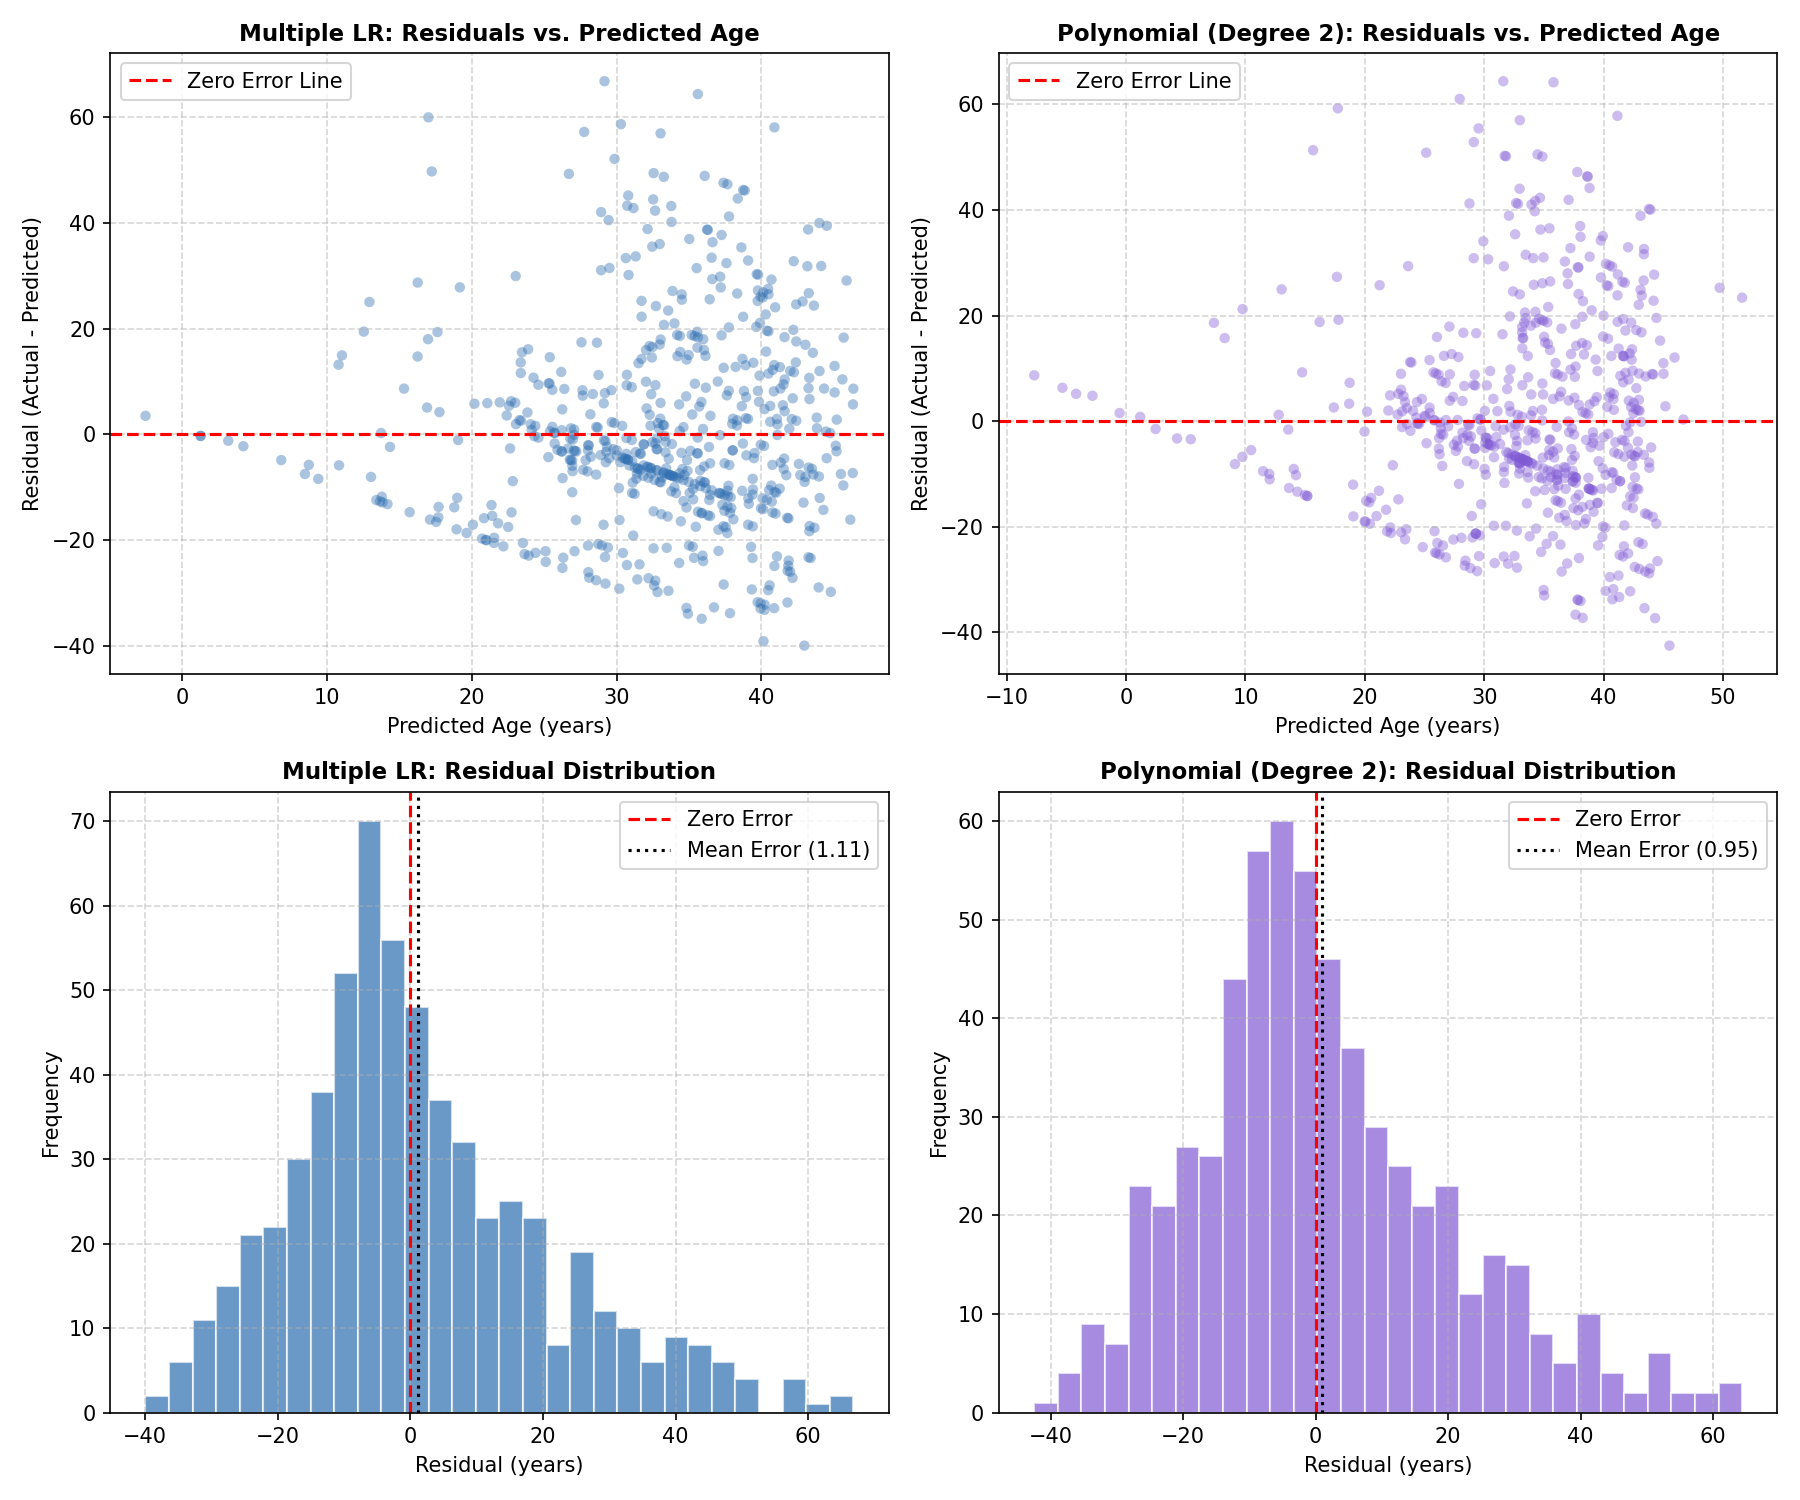

In [4]:
# Calculate residuals: residual = y_test - y_pred
res_mlr = y_test - y_pred_mlr
res_poly = y_test - y_pred_poly

# Residual summary statistics
print("Residual Summary Statistics on Test Set:")
print(f"Multiple LR:           Mean = {res_mlr.mean():.4f}, Std = {res_mlr.std():.4f}, Skew = {res_mlr.skew():.4f}")
print(f"Polynomial (degree 2): Mean = {res_poly.mean():.4f}, Std = {res_poly.std():.4f}, Skew = {res_poly.skew():.4f}")

# 2x2 Residual diagnostic figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Top Left: MLR Residuals vs Predicted Age
axes[0, 0].scatter(y_pred_mlr, res_mlr, color="#2b6cb0", alpha=0.4, edgecolors="none", s=25)
axes[0, 0].axhline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error Line")
axes[0, 0].set_title("Multiple LR: Residuals vs. Predicted Age", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Predicted Age (years)", fontsize=10)
axes[0, 0].set_ylabel("Residual (Actual - Predicted)", fontsize=10)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)
axes[0, 0].legend(frameon=True)

# Top Right: Polynomial Residuals vs Predicted Age
axes[0, 1].scatter(y_pred_poly, res_poly, color="#805ad5", alpha=0.4, edgecolors="none", s=25)
axes[0, 1].axhline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error Line")
axes[0, 1].set_title("Polynomial (Degree 2): Residuals vs. Predicted Age", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Predicted Age (years)", fontsize=10)
axes[0, 1].set_ylabel("Residual (Actual - Predicted)", fontsize=10)
axes[0, 1].grid(True, linestyle="--", alpha=0.5)
axes[0, 1].legend(frameon=True)

# Bottom Left: MLR Residual Distribution Histogram
axes[1, 0].hist(res_mlr, bins=30, color="#2b6cb0", edgecolor="white", alpha=0.7)
axes[1, 0].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error")
axes[1, 0].axvline(res_mlr.mean(), color="black", linestyle=":", linewidth=1.5, label=f"Mean Error ({res_mlr.mean():.2f})")
axes[1, 0].set_title("Multiple LR: Residual Distribution", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Residual (years)", fontsize=10)
axes[1, 0].set_ylabel("Frequency", fontsize=10)
axes[1, 0].legend(frameon=True)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Bottom Right: Polynomial Residual Distribution Histogram
axes[1, 1].hist(res_poly, bins=30, color="#805ad5", edgecolor="white", alpha=0.7)
axes[1, 1].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error")
axes[1, 1].axvline(res_poly.mean(), color="black", linestyle=":", linewidth=1.5, label=f"Mean Error ({res_poly.mean():.2f})")
axes[1, 1].set_title("Polynomial (Degree 2): Residual Distribution", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Residual (years)", fontsize=10)
axes[1, 1].set_ylabel("Frequency", fontsize=10)
axes[1, 1].legend(frameon=True)
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("visualizations/11_residual_analysis.png", dpi=150)
plt.show()


Error by Age Group on Holdout Test Set (Count, MAE, Mean Signed Error):
Age_Group  Count  Base_MAE  Base_Signed_Error  MLR_MAE  MLR_Signed_Error  Poly_MAE  Poly_Signed_Error
     0-12     93   28.4086            28.4086  20.7952           20.7194   20.6113            20.0222
    13-19     28   16.6429            16.6429  18.8432           18.8247   19.7307            19.6437
    20-39    278    6.0432             4.7698   7.2792            4.3459    7.3609             4.6337
    40-59    114   15.3333           -15.3333  11.1000          -10.9260   10.9857           -10.9275
      60+     87   39.0115           -39.0115  35.4185          -35.4185   34.7600           -34.7600



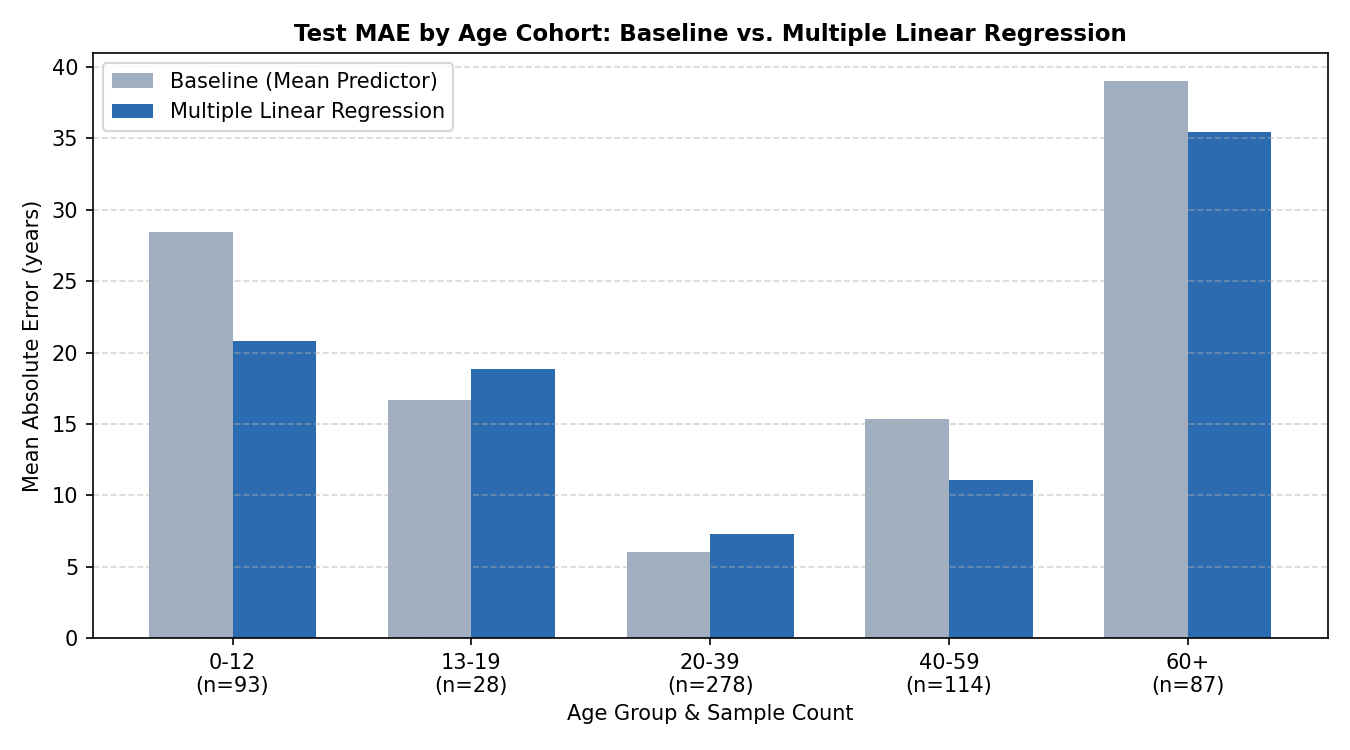

In [5]:
# Note: Age groups with small sample counts (e.g., 0-12, 13-19, 60+) produce noisier, higher-variance estimates.
bins = [0, 12, 19, 39, 59, 200]
labels = ["0-12", "13-19", "20-39", "40-59", "60+"]

# Partition test ground truth into age cohorts
age_group_series = pd.cut(y_test, bins=bins, labels=labels)
y_pred_base = np.full_like(y_test, y_train.mean())

records = []
for grp in labels:
    mask = (age_group_series == grp)
    cnt = int(mask.sum())
    y_true_g = y_test[mask]
    
    # Baseline metrics
    base_mae = np.abs(y_true_g - y_pred_base[mask]).mean()
    base_signed = (y_pred_base[mask] - y_true_g).mean()
    
    # Multiple LR metrics
    mlr_mae = np.abs(y_true_g - y_pred_mlr[mask]).mean()
    mlr_signed = (y_pred_mlr[mask] - y_true_g).mean()
    
    # Polynomial (degree 2) metrics
    poly_mae = np.abs(y_true_g - y_pred_poly[mask]).mean()
    poly_signed = (y_pred_poly[mask] - y_true_g).mean()
    
    records.append({
        "Age_Group": grp,
        "Count": cnt,
        "Base_MAE": base_mae,
        "Base_Signed_Error": base_signed,
        "MLR_MAE": mlr_mae,
        "MLR_Signed_Error": mlr_signed,
        "Poly_MAE": poly_mae,
        "Poly_Signed_Error": poly_signed
    })

df_age_errors = pd.DataFrame(records)
print("Error by Age Group on Holdout Test Set (Count, MAE, Mean Signed Error):")
print(df_age_errors.round(4).to_string(index=False))

# Bar chart of MAE per age group: Baseline vs Multiple LR
plt.figure(figsize=(9, 5))
x_indices = np.arange(len(labels))
bar_width = 0.35

x_labels_with_counts = [f"{grp}\n(n={cnt})" for grp, cnt in zip(df_age_errors["Age_Group"], df_age_errors["Count"])]

plt.bar(x_indices - bar_width/2, df_age_errors["Base_MAE"], width=bar_width, color="#a0aec0", label="Baseline (Mean Predictor)")
plt.bar(x_indices + bar_width/2, df_age_errors["MLR_MAE"], width=bar_width, color="#2b6cb0", label="Multiple Linear Regression")

plt.title("Test MAE by Age Cohort: Baseline vs. Multiple Linear Regression", fontsize=11, fontweight="bold")
plt.xlabel("Age Group & Sample Count", fontsize=10)
plt.ylabel("Mean Absolute Error (years)", fontsize=10)
plt.xticks(x_indices, x_labels_with_counts)
plt.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.legend(frameon=True)
plt.tight_layout()

plt.savefig("visualizations/12_error_by_age_group.png", dpi=150)
plt.show()


In [6]:
# Feature-group ablation study with LinearRegression on scaled data
ablation_configs = {
    "Demographics Only": dummy_cols,
    "Geometry Only": continuous_cols,
    "Both (Demographics + Geometry)": dummy_cols + continuous_cols
}

ablation_rows = []
for set_name, feature_subset in ablation_configs.items():
    model = LinearRegression().fit(X_train_mlr_s[feature_subset], y_train)
    y_tr_pred = model.predict(X_train_mlr_s[feature_subset])
    y_te_pred = model.predict(X_test_mlr_s[feature_subset])
    
    ablation_rows.append({
        "Feature_Set": set_name,
        "Train_R2": r2_score(y_train, y_tr_pred),
        "Test_R2": r2_score(y_test, y_te_pred),
        "Test_MAE": mean_absolute_error(y_test, y_te_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_te_pred))
    })

df_ablation = pd.DataFrame(ablation_rows)
print("Feature-Group Ablation Results (Linear Regression):")
print(df_ablation.round(4).to_string(index=False))

# Persist ablation findings
df_ablation.to_csv("data/processed/ce2_ablation_results.csv", index=False)
print("\nSaved ablation results to data/processed/ce2_ablation_results.csv")


Feature-Group Ablation Results (Linear Regression):
                   Feature_Set  Train_R2  Test_R2  Test_MAE  Test_RMSE
             Demographics Only    0.0764   0.0744   15.6530    20.2784
                 Geometry Only    0.1212   0.1152   15.5303    19.8263
Both (Demographics + Geometry)    0.1768   0.1719   14.7200    19.1813

Saved ablation results to data/processed/ce2_ablation_results.csv



## CE2 Phase 7: Cross-Validation

### 1. Purpose of $k$-Fold Cross-Validation
Evaluating a regression model solely on a single 600-row holdout test split provides only a single noisy point estimate. Test metrics can fluctuate significantly based purely on which samples happened to land in the test set. 

$k$-fold cross-validation mitigates this by:
1. Splitting the **TRAINING data only** into $k$ mutually exclusive, equal folds (here $k=5$).
2. Training the model on $k-1$ folds and evaluating it on the remaining held-out fold.
3. Repeating this process $k$ times so that every observation serves as a validation sample exactly once.
4. Computing the mean and standard deviation across all folds, yielding both the expected generalization performance and its empirical variance / stability.

---

### 2. Preventing Data Leakage Inside the CV Loop
A critical methodological requirement is that **feature scaling must occur strictly inside each cross-validation fold**. 
If a `StandardScaler` were fit on the entire training set before partitioning into folds, mean and variance information from the validation fold would leak into the training process, causing overly optimistic validation metrics. 

To prevent data leakage:
* Raw unscaled features are passed into a scikit-learn `Pipeline`.
* The `StandardScaler` is wrapped inside a `ColumnTransformer` within the pipeline.
* During each fold, `StandardScaler.fit_transform()` is executed exclusively on the $(k-1)$ training folds, and `StandardScaler.transform()` is applied to the single validation fold without refitting.


In [7]:
# Select best continuous feature using TRAINING data only
train_corrs = X_train[continuous_cols].apply(lambda col: col.corr(y_train))
best_feature = train_corrs.abs().idxmax()
print(f"Best continuous feature by training correlation: '{best_feature}' (Pearson r = {train_corrs[best_feature]:.4f})")
# Note: Selecting 'face_aspect_ratio' on the full training set prior to CV introduces a minor optimistic
# selection bias, which is practically negligible because its correlation decisively leads all other features.

# Build leakage-free pipelines from UNSCALED features (StandardScaler fits per fold)
prep_linear = ColumnTransformer([
    ("scale", StandardScaler(), continuous_cols),
    ("dummies", "passthrough", dummy_cols)
])

baseline_pipe = DummyRegressor(strategy="mean")

simple_pipe = Pipeline([
    ("prep", ColumnTransformer([("scale", StandardScaler(), [best_feature])])),
    ("reg", LinearRegression())
])

mlr_pipe = Pipeline([
    ("prep", prep_linear),
    ("reg", LinearRegression())
])

poly2_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("poly", Pipeline([
            ("scale", StandardScaler()),
            ("poly_features", PolynomialFeatures(degree=2, include_bias=False))
        ]), continuous_cols),
        ("dummies", "passthrough", dummy_cols)
    ])),
    ("reg", LinearRegression())
])

models_to_evaluate = {
    "Baseline (Mean)": baseline_pipe,
    f"Simple LR ({best_feature})": simple_pipe,
    "Multiple Linear Regression": mlr_pipe,
    "Polynomial Regression (degree 2)": poly2_pipe
}

# 5-fold cross-validation on TRAINING data only
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

cv_summary_rows = []
for model_name, model_pipe in models_to_evaluate.items():
    cv_res = cross_validate(model_pipe, X_train_mlr, y_train, cv=cv5, scoring=scoring, return_train_score=True)
    cv_summary_rows.append({
        "Model": model_name,
        "CV_R2_Mean": np.mean(cv_res["test_r2"]),
        "CV_R2_Std": np.std(cv_res["test_r2"]),
        "CV_MAE_Mean": -np.mean(cv_res["test_mae"]),
        "CV_MAE_Std": np.std(cv_res["test_mae"]),
        "CV_RMSE_Mean": -np.mean(cv_res["test_rmse"]),
        "CV_RMSE_Std": np.std(cv_res["test_rmse"]),
        "Train_R2_Mean": np.mean(cv_res["train_r2"])
    })

df_cv_summary = pd.DataFrame(cv_summary_rows)
print("\n5-Fold Cross-Validation Summary Table (Training Data Only):")
print(df_cv_summary.round(4).to_string(index=False))


Best continuous feature by training correlation: 'face_aspect_ratio' (Pearson r = 0.2585)

5-Fold Cross-Validation Summary Table (Training Data Only):
                           Model  CV_R2_Mean  CV_R2_Std  CV_MAE_Mean  CV_MAE_Std  CV_RMSE_Mean  CV_RMSE_Std  Train_R2_Mean
                 Baseline (Mean)     -0.0025     0.0034      15.5059      0.2434       20.0604       0.5589         0.0000
   Simple LR (face_aspect_ratio)      0.0638     0.0218      15.2646      0.3390       19.3871       0.6777         0.0670
      Multiple Linear Regression      0.1637     0.0139      13.9283      0.1633       18.3230       0.5747         0.1781
Polynomial Regression (degree 2)      0.1427     0.0365      13.9848      0.2258       18.5484       0.6956         0.1992



In [8]:
# Sensitivity of Cross-Validation performance to choice of k (Multiple Linear Regression)
k_values = [3, 5, 10]
k_sensitivity_rows = []

for k in k_values:
    cv_k = KFold(n_splits=k, shuffle=True, random_state=42)
    res_k = cross_validate(mlr_pipe, X_train_mlr, y_train, cv=cv_k, scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
    k_sensitivity_rows.append({
        "k_folds": k,
        "CV_R2_Mean": np.mean(res_k["test_r2"]),
        "CV_R2_Std": np.std(res_k["test_r2"]),
        "CV_MAE_Mean": -np.mean(res_k["test_mae"]),
        "CV_MAE_Std": np.std(res_k["test_mae"])
    })

df_k_sensitivity = pd.DataFrame(k_sensitivity_rows)
print("Multiple Linear Regression Performance across k = [3, 5, 10]:")
print(df_k_sensitivity.round(4).to_string(index=False))


Multiple Linear Regression Performance across k = [3, 5, 10]:
 k_folds  CV_R2_Mean  CV_R2_Std  CV_MAE_Mean  CV_MAE_Std
       3      0.1623     0.0097      13.9509      0.0825
       5      0.1637     0.0139      13.9283      0.1633
      10      0.1647     0.0287      13.9282      0.5583



In [9]:
from sklearn.model_selection import cross_val_score

# Paired 5-fold comparison between Multiple LR and Polynomial Regression (degree 2)
scores_mlr = cross_val_score(mlr_pipe, X_train_mlr, y_train, cv=cv5, scoring="r2")
scores_poly = cross_val_score(poly2_pipe, X_train_mlr, y_train, cv=cv5, scoring="r2")

fold_diffs = scores_poly - scores_mlr
poly_wins = int(np.sum(fold_diffs > 0))

df_paired_folds = pd.DataFrame({
    "Fold": [f"Fold {i+1}" for i in range(5)],
    "MLR_R2": scores_mlr,
    "Poly2_R2": scores_poly,
    "Difference (Poly2 - MLR)": fold_diffs
})

print("Paired 5-Fold Validation R² Scores:")
print(df_paired_folds.round(4).to_string(index=False))
print(f"\nMean Fold Difference (Poly2 minus MLR): {fold_diffs.mean():.4f}")
print(f"Polynomial (degree 2) outperforms Multiple LR in {poly_wins} out of 5 folds.")


Paired 5-Fold Validation R² Scores:
  Fold  MLR_R2  Poly2_R2  Difference (Poly2 - MLR)
Fold 1  0.1902    0.1936                    0.0034
Fold 2  0.1646    0.1524                   -0.0122
Fold 3  0.1549    0.1522                   -0.0027
Fold 4  0.1553    0.1341                   -0.0212
Fold 5  0.1534    0.0811                   -0.0723

Mean Fold Difference (Poly2 minus MLR): -0.0210
Polynomial (degree 2) outperforms Multiple LR in 1 out of 5 folds.



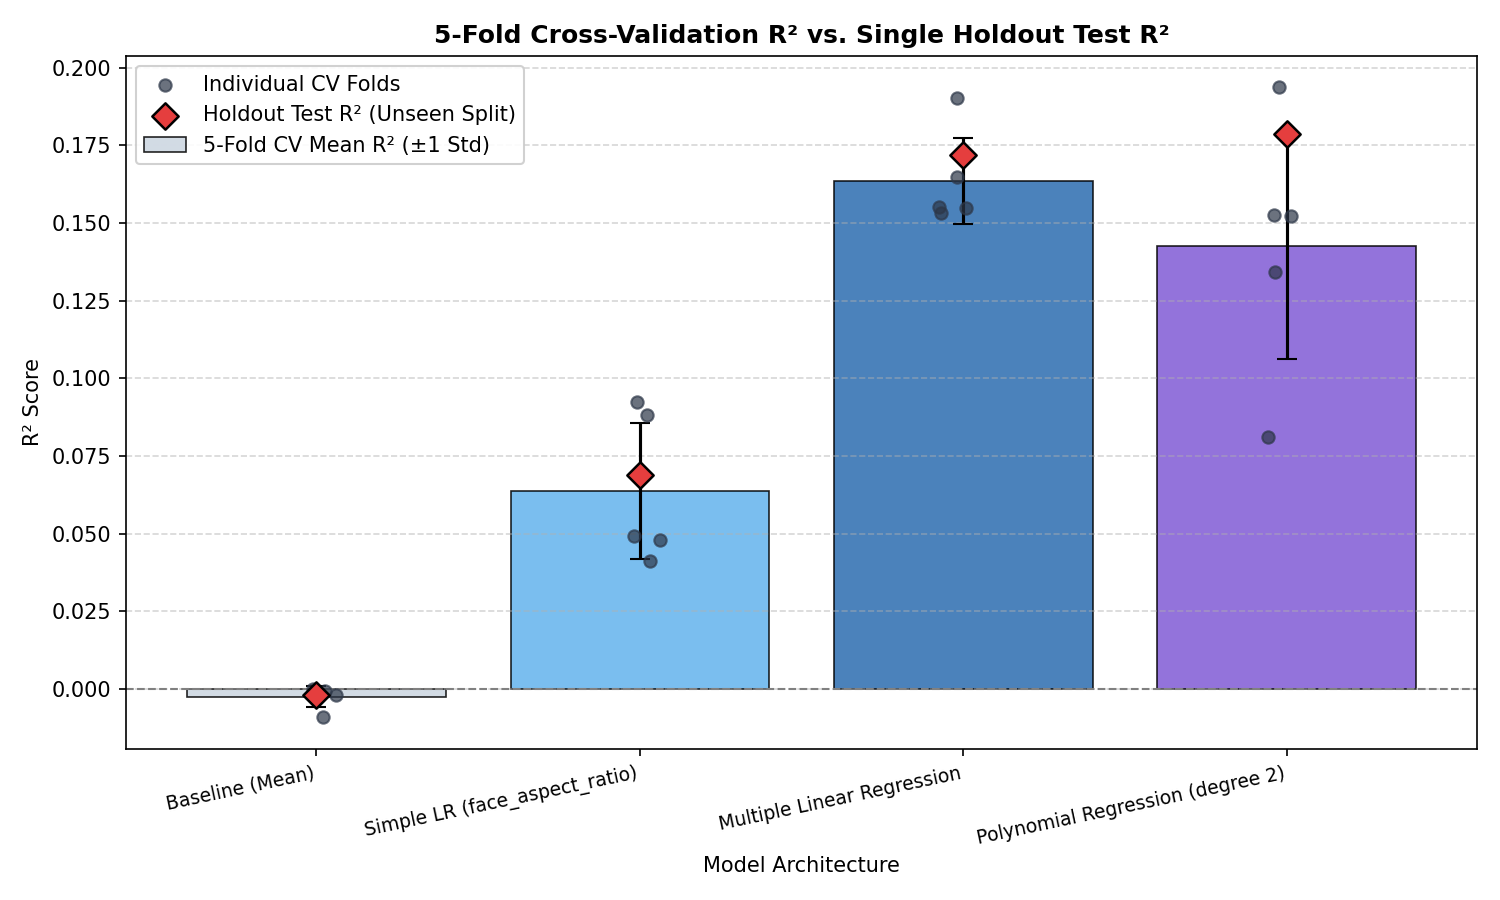

In [10]:
# Retrieve holdout test R² scores from ce2_model_results.csv
model_name_map = {
    "Baseline (Mean)": "Baseline (Mean)",
    f"Simple LR ({best_feature})": f"Simple LR ({best_feature})",
    "Multiple Linear Regression": "Multiple Linear Regression",
    "Polynomial Regression (degree 2)": "Polynomial Regression (degree 2)"
}

test_r2_values = []
for model_name in df_cv_summary["Model"]:
    matched_test_r2 = df_results.loc[df_results["Model"] == model_name, "Test_R2"].values[0]
    test_r2_values.append(matched_test_r2)

# Gather per-fold scores for each model for scatter overlay
all_fold_scores = []
for model_name, model_pipe in models_to_evaluate.items():
    f_scores = cross_val_score(model_pipe, X_train_mlr, y_train, cv=cv5, scoring="r2")
    all_fold_scores.append(f_scores)

# Bar chart of CV Mean R2 with error bars (std), overlaid fold dots, and holdout test diamonds
plt.figure(figsize=(10, 6))
x_pos = np.arange(len(df_cv_summary))

# Bar chart
plt.bar(x_pos, df_cv_summary["CV_R2_Mean"], yerr=df_cv_summary["CV_R2_Std"],
        capsize=5, color=["#cbd5e0", "#63b3ed", "#2b6cb0", "#805ad5"],
        alpha=0.85, edgecolor="black", linewidth=0.8, label="5-Fold CV Mean R² (±1 Std)")

# Overlay individual fold points
np.random.seed(42)
for i, f_scores in enumerate(all_fold_scores):
    jitter = np.random.normal(0, 0.04, size=len(f_scores))
    if i == 0:
        plt.scatter(x_pos[i] + jitter, f_scores, color="#2d3748", alpha=0.7, s=35, zorder=4, label="Individual CV Folds")
    else:
        plt.scatter(x_pos[i] + jitter, f_scores, color="#2d3748", alpha=0.7, s=35, zorder=4)

# Overlay holdout test set R² with red diamonds
plt.scatter(x_pos, test_r2_values, color="#e53e3e", marker="D", s=80, edgecolors="black", linewidth=1.2,
            zorder=5, label="Holdout Test R² (Unseen Split)")

plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("5-Fold Cross-Validation R² vs. Single Holdout Test R²", fontsize=12, fontweight="bold")
plt.xlabel("Model Architecture", fontsize=10)
plt.ylabel("R² Score", fontsize=10)
plt.xticks(x_pos, df_cv_summary["Model"], rotation=12, ha="right", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper left")
plt.tight_layout()

plt.savefig("visualizations/13_cross_validation_comparison.png", dpi=150)
plt.show()


In [11]:
# Persist cross-validation results to disk
cv_results_path = "data/processed/ce2_cv_results.csv"
df_cv_summary.to_csv(cv_results_path, index=False)
print(f"Cross-validation summary successfully saved to: {cv_results_path}")
print("File confirmation:")
print(pd.read_csv(cv_results_path).round(4).to_string(index=False))


Cross-validation summary successfully saved to: data/processed/ce2_cv_results.csv
File confirmation:
                           Model  CV_R2_Mean  CV_R2_Std  CV_MAE_Mean  CV_MAE_Std  CV_RMSE_Mean  CV_RMSE_Std  Train_R2_Mean
                 Baseline (Mean)     -0.0025     0.0034      15.5059      0.2434       20.0604       0.5589         0.0000
   Simple LR (face_aspect_ratio)      0.0638     0.0218      15.2646      0.3390       19.3871       0.6777         0.0670
      Multiple Linear Regression      0.1637     0.0139      13.9283      0.1633       18.3230       0.5747         0.1781
Polynomial Regression (degree 2)      0.1427     0.0365      13.9848      0.2258       18.5484       0.6956         0.1992



### Observation

*(This section is reserved for user observations and synthesis of error patterns, ablation insights, and cross-validation variance across models.)*
